# Семинар 5 — вариант 57: география и границы территорий

Данные загружаются напрямую из Wikidata Query Service. P47 означает соседство по суше, воде или общей точке. Отдельные типы границы выводятся только из явных квалификаторов P47 или класса связанного объекта границы P805; если свидетельства нет, тип остаётся неизвестным. Одна пара может иметь и сухопутную, и морскую границу. Для «по точке» требуется явное свидетельство об объекте-точке.

Ресурсные связи: P47 (соседство), P36 (столица), P37 (официальный язык), P38 (валюта), P30 (континент). Производные связи стран по общему официальному языку или общей валюте показаны в RDF и отдельной таблице. Для честной оценки KGE они не используются: эти связи вычисляются из P37/P38 и могли бы раскрыть отложенные факты.

Параметры: seed=2083, d=12, p=q=1, margin=1. Запросы, время выгрузки, ответы и результаты сохраняются в results/.

## 1. Прямые SPARQL-запросы к Wikidata

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json, time, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdflib import Graph, Namespace, Literal
from rdflib.namespace import XSD

SEED, DIM, MARGIN = 2083, 12, 1.0
P = Q = 1.0
rng = np.random.default_rng(SEED)
OUTPUT = Path.cwd() / 'results'
OUTPUT.mkdir(exist_ok=True)
ENDPOINT = 'https://query.wikidata.org/sparql'
HEADERS = {'Accept': 'application/sparql-results+json',
           'User-Agent': 'SemanticTechnologiesSeminar57/1.0 (educational notebook)'}
PREFIXES = '''PREFIX wd: <http://www.wikidata.org/entity/>
PREFIX wdt: <http://www.wikidata.org/prop/direct/>'''
BORDERS_QUERY = PREFIXES + '''
PREFIX p: <http://www.wikidata.org/prop/>
PREFIX ps: <http://www.wikidata.org/prop/statement/>
PREFIX pq: <http://www.wikidata.org/prop/qualifier/>
SELECT ?country ?neighbor ?statement ?borderItem ?criterion ?nature WHERE {
  ?country wdt:P31 wd:Q3624078 ; wdt:P47 ?neighbor ; p:P47 ?statement .
  ?neighbor wdt:P31 wd:Q3624078 .
  ?statement ps:P47 ?neighbor .
  FILTER(?country != ?neighbor)
  OPTIONAL { ?statement pq:P805 ?borderItem }
  OPTIONAL { ?statement pq:P1013 ?criterion }
  OPTIONAL { ?statement pq:P5102 ?nature }
}'''
ATTRIBUTES_QUERY = PREFIXES + '''
SELECT ?country ?relation ?tail WHERE {
  ?country wdt:P31 wd:Q3624078 .
  VALUES ?relation { wdt:P36 wdt:P37 wdt:P38 wdt:P30 }
  ?country ?relation ?tail .
}'''
BORDER_TYPES_QUERY = PREFIXES + '''
PREFIX p: <http://www.wikidata.org/prop/>
PREFIX ps: <http://www.wikidata.org/prop/statement/>
PREFIX pq: <http://www.wikidata.org/prop/qualifier/>
SELECT ?country ?neighbor ?borderItem ?kind WHERE {
  ?country wdt:P31 wd:Q3624078 ; wdt:P47 ?neighbor ; p:P47 ?statement .
  ?neighbor wdt:P31 wd:Q3624078 .
  ?statement ps:P47 ?neighbor ; pq:P805 ?borderItem .
  OPTIONAL { ?borderItem wdt:P31 ?kind }
}'''
BORDER_FEATURES_QUERY = PREFIXES + '''
PREFIX p: <http://www.wikidata.org/prop/>
PREFIX ps: <http://www.wikidata.org/prop/statement/>
PREFIX pq: <http://www.wikidata.org/prop/qualifier/>
SELECT ?country ?neighbor ?borderItem ?feature ?featureProperty WHERE {
  ?country wdt:P31 wd:Q3624078 ; wdt:P47 ?neighbor ; p:P47 ?statement .
  ?neighbor wdt:P31 wd:Q3624078 .
  ?statement ps:P47 ?neighbor ; pq:P805 ?borderItem .
  VALUES ?featureProperty { wdt:P706 wdt:P206 }
  ?borderItem ?featureProperty ?feature .
}'''
def query_wikidata(query):
    for attempt in range(3):
        response = requests.get(ENDPOINT, params={'query': query},
                                headers=HEADERS, timeout=65)
        if response.status_code in (429, 502, 503, 504) and attempt < 2:
            time.sleep(int(response.headers.get('Retry-After', '5')))
            continue
        response.raise_for_status()
        return response.json()['results']['bindings']

retrieved_at = datetime.now(timezone.utc).isoformat()
border_rows = query_wikidata(BORDERS_QUERY)
attribute_rows = query_wikidata(ATTRIBUTES_QUERY)
border_type_rows = query_wikidata(BORDER_TYPES_QUERY)
border_feature_rows = query_wikidata(BORDER_FEATURES_QUERY)
# Пакетный запрос названий для объектов границ и физических объектов.
label_ids = sorted(
    {row['borderItem']['value'].rsplit('/',1)[-1] for row in border_rows
     if 'borderItem' in row}
    | {row['feature']['value'].rsplit('/',1)[-1] for row in border_feature_rows}
)
LABELS_QUERY = PREFIXES + '''
PREFIX wikibase: <http://wikiba.se/ontology#>
PREFIX bd: <http://www.bigdata.com/rdf#>
SELECT ?item ?itemLabel WHERE {
  VALUES ?item { ''' + ' '.join('wd:' + item for item in label_ids) + ''' }
  SERVICE wikibase:label { bd:serviceParam wikibase:language "ru,en". }
}'''
label_rows = query_wikidata(LABELS_QUERY)
print('P47 statements:', len(border_rows), 'attributes:', len(attribute_rows),
      'border object classes:', len(border_type_rows),
      'physical features:', len(border_feature_rows),
      'labels:', len(label_rows), 'UTC:', retrieved_at)

P47 statements: 837 attributes: 1033 border object classes: 2522 physical features: 73 labels: 456 UTC: 2026-10-28T18:35:23.660095+00:00


## 2. RDF-граф: тип границы, объект и общие свойства

Каждая запись P47 сохраняет происхождение: URI утверждения, квалификаторы и пограничный объект P805, если он указан. Типы ex:bordersByLand, ex:bordersByWater и ex:bordersAtPoint — производные связи с указанным ниже свидетельством. Отсутствующий тип обозначен как unknown в таблице, не приписывается суше автоматически. Объект границы P805 и географический объект P706/P206 добавляются к отдельному ресурсу пары ex:border_Q..._Q... . P706/P206 называют объект, связанный с границей, но не доказывают, что именно по нему проходит вся граница.

Общие язык и валюта вычисляются сравнением P37/P38 между государствами; конкретный общий объект записан в results/shared_attributes.tsv. Число соседей в извлечённой выборке хранится как xsd:integer и не считается загруженным из Wikidata фактом.

In [2]:
from collections import Counter, defaultdict
from itertools import combinations

def qid(uri):
    return uri.rsplit('/', 1)[-1]

def pair_of(a, b):
    return tuple(sorted((a, b)))

raw_borders = {(qid(x['country']['value']), qid(x['neighbor']['value']))
               for x in border_rows}
countries = sorted({e for pair in raw_borders for e in pair})
country_set = set(countries)
border_pairs = sorted({pair_of(*pair) for pair in raw_borders})
relations = ['P47', 'P36', 'P37', 'P38', 'P30']
triples = sorted(
    {(h, 'P47', t) for a, b in border_pairs for h, t in ((a, b), (b, a))}
    | {(qid(x['country']['value']), qid(x['relation']['value']), qid(x['tail']['value']))
       for x in attribute_rows if qid(x['country']['value']) in country_set}
)
entities = sorted({e for h, _, t in triples for e in (h, t)})
assert len(border_pairs) > 20

# Evidence: P47 qualifier or P31 of the P805 border item.
KIND_QIDS = {'Q15104814': 'land', 'Q3089219': 'water',
             'Q27345018': 'point', 'Q1540416': 'point'}
evidence = defaultdict(lambda: {'kinds': set(), 'border_objects': set(),
                                'features': set(), 'statements': set()})
for row in border_rows:
    pair = pair_of(qid(row['country']['value']), qid(row['neighbor']['value']))
    item = evidence[pair]
    item['statements'].add(row['statement']['value'])
    if 'borderItem' in row:
        item['border_objects'].add(qid(row['borderItem']['value']))
    for field in ('criterion', 'nature'):
        if field in row:
            kind = KIND_QIDS.get(qid(row[field]['value']))
            if kind:
                item['kinds'].add(kind)
for row in border_type_rows:
    if 'kind' in row:
        kind = KIND_QIDS.get(qid(row['kind']['value']))
        if kind:
            pair = pair_of(qid(row['country']['value']), qid(row['neighbor']['value']))
            evidence[pair]['kinds'].add(kind)
for row in border_feature_rows:
    pair = pair_of(qid(row['country']['value']), qid(row['neighbor']['value']))
    evidence[pair]['features'].add(qid(row['feature']['value']))

labels = {qid(row['item']['value']):row['itemLabel']['value']
          for row in label_rows if 'itemLabel' in row}
pd.DataFrame(sorted(labels.items()), columns=['qid','label']).to_csv(
    OUTPUT / 'wikidata_labels.tsv', sep='\t', index=False)

detail_rows = []
typed_border_triples = set()
for a, b in border_pairs:
    item = evidence[(a,b)]
    for kind in item['kinds']:
        relation = {'land':'bordersByLand', 'water':'bordersByWater',
                    'point':'bordersAtPoint'}[kind]
        typed_border_triples.update({(a,relation,b),(b,relation,a)})
    detail_rows.append({
        'country_1':a, 'country_2':b,
        'types':'|'.join(sorted(item['kinds'])) or 'unknown',
        'border_objects':'|'.join(sorted(item['border_objects'])),
        'border_object_names':'|'.join(labels.get(x,x) for x in sorted(item['border_objects'])),
        'physical_features':'|'.join(sorted(item['features'])),
        'physical_feature_names':'|'.join(labels.get(x,x) for x in sorted(item['features'])),
        'source_statements':'|'.join(sorted(item['statements'])),
    })
border_details = pd.DataFrame(detail_rows)

# Shared properties are derived from all countries, not just neighboring pairs.
shared_rows = set()
for property_id, shared_relation in [('P37','sharesOfficialLanguageWith'),
                                      ('P38','sharesCurrencyWith')]:
    by_object = defaultdict(set)
    for head, relation, tail in triples:
        if relation == property_id:
            by_object[tail].add(head)
    for common_object, heads in by_object.items():
        for a, b in combinations(sorted(heads), 2):
            shared_rows.add((a, shared_relation, b, common_object))
shared_attributes = pd.DataFrame(sorted(shared_rows),
    columns=['country_1','relation','country_2','shared_object'])

WD = Namespace('http://www.wikidata.org/entity/')
WDT = Namespace('http://www.wikidata.org/prop/direct/')
EX = Namespace('https://example.org/geography57/')
graph = Graph()
for prefix, namespace in [('wd',WD),('wdt',WDT),('ex',EX)]:
    graph.bind(prefix, namespace)
for h, r, t in triples:
    graph.add((WD[h], WDT[r], WD[t]))
for h, r, t in typed_border_triples:
    graph.add((WD[h], EX[r], WD[t]))
for a, relation, b, common_object in shared_rows:
    graph.add((WD[a], EX[relation], WD[b]))
    graph.add((WD[b], EX[relation], WD[a]))
for a, b in border_pairs:
    pair_node = EX[f'border_{a}_{b}']
    graph.add((pair_node, EX.territoryA, WD[a]))
    graph.add((pair_node, EX.territoryB, WD[b]))
    item = evidence[(a,b)]
    for kind in item['kinds']:
        graph.add((pair_node, EX.borderKind, EX[kind]))
    for border_object in item['border_objects']:
        graph.add((pair_node, EX.borderObject, WD[border_object]))
    for feature in item['features']:
        graph.add((pair_node, EX.physicalFeature, WD[feature]))
degree = pd.Series([h for h, r, t in triples if r == 'P47']).value_counts()
for country in countries:
    graph.add((WD[country], EX.neighborCountInExtract,
               Literal(int(degree[country]), datatype=XSD.integer)))

graph.serialize(destination=str(OUTPUT / 'geography57.ttl'), format='turtle')
pd.DataFrame(triples, columns=['head','relation','tail']).to_csv(
    OUTPUT / 'triples.tsv', sep='\t', index=False)
border_details.to_csv(OUTPUT / 'border_details.tsv', sep='\t', index=False)
shared_attributes.to_csv(OUTPUT / 'shared_attributes.tsv', sep='\t', index=False)
for name, query, rows in [
    ('borders', BORDERS_QUERY, border_rows),
    ('attributes', ATTRIBUTES_QUERY, attribute_rows),
    ('border_types', BORDER_TYPES_QUERY, border_type_rows),
    ('border_features', BORDER_FEATURES_QUERY, border_feature_rows),
    ('labels', LABELS_QUERY, label_rows),
]:
    (OUTPUT / f'{name}.sparql').write_text(query, encoding='utf-8')
    (OUTPUT / f'{name}_response.json').write_text(
        json.dumps(rows, ensure_ascii=False, indent=2), encoding='utf-8')
print('Стран:', len(countries), 'пар P47:', len(border_pairs),
      'сущностей KGE:', len(entities))
print('Прямых и симметризованных KGE-троек:', len(triples),
      'типизированных связей границы:', len(typed_border_triples),
      'общих языков/валют:', len(shared_attributes),
      'числовых литералов:', len(countries),
      'всего RDF-троек:', len(graph))
print('Типы пар:', border_details['types'].value_counts().to_dict())
print('Отношения KGE:', Counter(r for _,r,_ in triples))
sample = Graph()
for prefix, namespace in [('wd',WD),('wdt',WDT),('ex',EX)]:
    sample.bind(prefix, namespace)
for s, p, o in graph.triples((WD.Q183, None, None)):
    if p in (WDT.P47, WDT.P37, WDT.P38, EX.neighborCountInExtract) and (
        p != WDT.P47 or o == WD.Q142):
        sample.add((s,p,o))
print('Пример Turtle:\n', sample.serialize(format='turtle'))
print('Примеры подробностей границ:')
print(border_details[border_details.border_objects.ne('')].head(3).to_string(index=False))

Стран: 196 пар P47: 433 сущностей KGE: 757
Прямых и симметризованных KGE-троек: 1875 типизированных связей границы: 1050 общих языков/валют: 3030 числовых литералов: 196 всего RDF-троек: 10943
Типы пар: {'land': 199, 'land|water': 121, 'water': 84, 'unknown': 29}
Отношения KGE: Counter({'P47': 866, 'P37': 379, 'P38': 221, 'P36': 205, 'P30': 204})
Пример Turtle:
 @prefix ex: <https://example.org/geography57/> .
@prefix wd: <http://www.wikidata.org/entity/> .
@prefix wdt: <http://www.wikidata.org/prop/direct/> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

wd:Q183 wdt:P37 wd:Q188 ;
    wdt:P38 wd:Q4916 ;
    wdt:P47 wd:Q142 ;
    ex:neighborCountInExtract 9 .


Примеры подробностей границ:
country_1 country_2 types border_objects                border_object_names physical_features physical_feature_names                                                                                                                                                       source_statements
    Q1000  

## 3. Два SPARQL-запроса к построенному RDF-графу

Первый запрос показывает соседей Германии из извлечённых P47. Второй сортирует страны по числу соседей в этой же выгрузке; значение записано как типизированный числовой литерал. Запросы к публичному WDQS, из которых строится граф, также видны выше и сохранены в results/.

In [3]:
Q_NEIGHBORS = '''
PREFIX wd: <http://www.wikidata.org/entity/>
PREFIX wdt: <http://www.wikidata.org/prop/direct/>
SELECT ?neighbor WHERE { wd:Q183 wdt:P47 ?neighbor } ORDER BY ?neighbor
'''
Q_TOP_DEGREE = '''
PREFIX ex: <https://example.org/geography57/>
SELECT ?country ?count WHERE {
  ?country ex:neighborCountInExtract ?count .
} ORDER BY DESC(?count) ?country LIMIT 5
'''
neighbors_germany = [qid(str(row.neighbor)) for row in graph.query(Q_NEIGHBORS)]
top_degree = [(qid(str(row.country)), int(row['count']))
              for row in graph.query(Q_TOP_DEGREE)]
print('Соседи Германии по P47:', neighbors_germany)
print('Топ-5 по числу соседей в извлечённом графе:', top_degree)
assert int(graph.value(WD.Q183, EX.neighborCountInExtract)) == len(neighbors_germany)

Соседи Германии по P47: ['Q142', 'Q213', 'Q29999', 'Q31', 'Q32', 'Q36', 'Q39', 'Q40', 'Q756617']
Топ-5 по числу соседей в извлечённом графе: [('Q142', 18), ('Q148', 18), ('Q159', 17), ('Q30', 16), ('Q717', 14)]


## 4. Разбиение прямых отношений для KGE

Для P47 оба направления одной пары остаются в одной части. P36, P37, P38 и P30 откладываются только при условии, что нужные сущности встречаются в train. Производные типы границ и общие язык/валюта не входят в KGE: они созданы из исходных утверждений и могли бы раскрыть правильные ответы в тесте. Проверка охватывает все пять прямых отношений.

In [4]:
local = np.random.default_rng(SEED)
shuffled = [border_pairs[i] for i in local.permutation(len(border_pairs))]
n_valid = max(1, round(0.1 * len(shuffled)))
n_test = max(1, round(0.1 * len(shuffled)))
valid_pairs = set(shuffled[:n_valid])
test_pairs = set(shuffled[n_valid:n_valid+n_test])
train_pairs = set(shuffled[n_valid+n_test:])
def border_triples(pairs):
    return [(h, 'P47', t) for a, b in sorted(pairs)
            for h, t in ((a, b), (b, a))]

auxiliary = [triple for triple in triples if triple[1] != 'P47']
border_train_entities = {e for pair in train_pairs for e in pair}
aux_train = set(auxiliary)
aux_valid, aux_test = set(), set()
for relation in [r for r in relations if r != 'P47']:
    relation_triples = sorted(t for t in auxiliary if t[1] == relation)
    target = 1 if relation == 'P36' else max(1, round(0.1 * len(relation_triples)))
    order = local.permutation(len(relation_triples))
    for destination in (aux_valid, aux_test):
        for i in order:
            triple = relation_triples[i]
            head, _, tail = triple
            if len([t for t in destination if t[1] == relation]) >= target:
                break
            if triple not in aux_train or head not in border_train_entities:
                continue
            if sum(t[2] == tail and t[1] == relation for t in aux_train) <= 1:
                continue
            aux_train.remove(triple)
            destination.add(triple)
        assert any(t[1] == relation for t in destination), relation

train = sorted(aux_train | set(border_triples(train_pairs)))
valid = sorted(aux_valid | set(border_triples(valid_pairs)))
test = sorted(aux_test | set(border_triples(test_pairs)))
train_entities = {e for h, _, t in train for e in (h, t)}
assert {e for h, _, t in valid+test for e in (h, t)} <= train_entities
assert not (set(train)&set(valid) or set(train)&set(test) or set(valid)&set(test))
assert {r for _, r, _ in train} == {r for _, r, _ in valid} == {r for _, r, _ in test} == set(relations)
assert {tuple(sorted((h,t))) for h,r,t in valid if r=='P47'}.isdisjoint(
    {tuple(sorted((h,t))) for h,r,t in train+test if r=='P47'})
assert {tuple(sorted((h,t))) for h,r,t in test if r=='P47'}.isdisjoint(
    {tuple(sorted((h,t))) for h,r,t in train+valid if r=='P47'})
for name, data in [('train',train), ('validation',valid), ('test',test)]:
    pd.DataFrame(data, columns=['head','relation','tail']).to_csv(
        OUTPUT / f'{name}.tsv', sep='\t', index=False)
    print(name, len(data), pd.Series([r for _,r,_ in data]).value_counts().to_dict())

train 1541 {'P47': 694, 'P37': 303, 'P36': 203, 'P38': 177, 'P30': 164}
validation 167 {'P47': 86, 'P37': 38, 'P38': 22, 'P30': 20, 'P36': 1}
test 167 {'P47': 86, 'P37': 38, 'P38': 22, 'P30': 20, 'P36': 1}


## 5. Структурные эмбеддинги: прогулки только по train, затем SVD

In [5]:
# Граф соседства строим ТОЛЬКО по обучающим фактам.
neighbors = {e:set() for e in entities}
for h, r, t in train:
    neighbors[h].add(t)
    neighbors[t].add(h)

walks = []
for start in entities:
    for _ in range(12):
        walk = [start]
        for step in range(10):
            options = sorted(neighbors[walk[-1]])
            if not options:
                break
            walk.append(rng.choice(options))
        walks.append(walk)

entity_id = {e:i for i,e in enumerate(entities)}
co = np.zeros((len(entities),len(entities)))
for walk in walks:
    for i, word in enumerate(walk):
        for other in walk[max(0,i-2):i+3]:
            if word != other:
                co[entity_id[word],entity_id[other]] += 1

# Логарифм сглаживает слишком частые соседства; SVD сжимает матрицу.
u, s, vt = np.linalg.svd(np.log1p(co),full_matrices=False)
walk_vectors = u[:, :DIM] * np.sqrt(s[:DIM])

def cosine(a, b):
    return float(np.dot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b)+1e-9))

sample = 'Q183'
scores = [(e,cosine(walk_vectors[entity_id[sample]], walk_vectors[entity_id[e]]))
          for e in entities if e != sample]
print('Ближайшие по структуре к Германии (не обязательно географически!):')
print(sorted(scores,key=lambda x:-x[1])[:5])
for other in ['Q40', 'Q142', 'Q45']:
    print('Близость DE и', other, ':', round(cosine(walk_vectors[entity_id['Q183']], walk_vectors[entity_id[other]]),3))

Ближайшие по структуре к Германии (не обязательно географически!):
[('Q31', 0.9894989505034469), ('Q64', 0.9803496603851766), ('Q238', 0.9755408802764884), ('Q239', 0.9722591500455986), ('Q4916', 0.969980069830133)]
Близость DE и Q40 : 0.959
Близость DE и Q142 : 0.763
Близость DE и Q45 : 0.936


## 6. Индексы и допустимые типы концов связей

In [6]:
relation_id = {r:i for i,r in enumerate(relations)}
def to_ids(data):
    return np.array([(entity_id[h],relation_id[r],entity_id[t]) for h,r,t in data],
                    dtype=int).reshape(-1,3)
train_ids, valid_ids, test_ids = map(to_ids, (train,valid,test))
tail_types = {'P47': countries}
tail_types.update({r:sorted({t for _,rel,t in triples if rel==r})
                   for r in relations if r!='P47'})
possible_tails = {relation_id[r]:np.array([entity_id[t] for t in values])
                  for r,values in tail_types.items()}
train_set = set(map(tuple,train_ids))
all_set = set(map(tuple,to_ids(triples)))
print('Форма матрицы сущностей:', (len(entities),DIM))

Форма матрицы сущностей: (757, 12)


## 7. Обучаем TransE и DistMult

TransE уменьшает L1-расстояние между h+r и t. DistMult вычисляет сумму покоординатных произведений. Это учебные реализации на NumPy. Размер графа теперь зависит от живого запроса, поэтому используется 35 эпох.

In [7]:
def score_transe(E, R, h, r, tails):
    return -np.abs(E[h] + R[r] - E[tails]).sum(axis=1)

def score_distmult(E, R, h, r, tails):
    return (E[h] * R[r] * E[tails]).sum(axis=1)

def wrong_tail(h, r, t):
    # В обучении считаем известными только train-тройки.
    options = [x for x in possible_tails[r]
               if x != t and (relations[int(r)] != 'P47' or int(x) != int(h))
               and (h,r,int(x)) not in train_set]
    return int(rng.choice(options)) if options else None

In [8]:
def train_model(model, epochs=35, lr=0.015):
    local = np.random.default_rng(SEED + (1 if model == 'TransE' else 2))
    E = local.normal(0, 0.18, (len(entities),DIM))
    R = local.normal(0, 0.18, (len(relations),DIM))
    mE = np.zeros_like(E); vE = np.zeros_like(E)
    mR = np.zeros_like(R); vR = np.zeros_like(R)
    step = 0
    losses = []

    for epoch in range(epochs):
        order = local.permutation(len(train_ids))
        epoch_loss = 0
        for start in range(0, len(order), 32):
            batch = train_ids[order[start:start+32]]
            bad = []
            for h,r,t in batch:
                options = [int(x) for x in possible_tails[r]
                           if x != t and (relations[int(r)] != 'P47' or int(x) != int(h))
                           and (int(h),int(r),int(x)) not in train_set]
                bad.append(int(local.choice(options)) if options else int(t))
            bad = np.array(bad)
            # Если единственный возможный ответ, не обновляем по такой тройке.
            mask = bad != batch[:,2]
            h,r,t = batch[mask].T
            n = bad[mask]
            if len(h)==0: continue
            gE = np.zeros_like(E); gR = np.zeros_like(R)
            H, V, T, N = E[h], R[r], E[t], E[n]
            if model == 'TransE':
                pos = np.abs(H+V-T).sum(axis=1)
                neg = np.abs(H+V-N).sum(axis=1)
                active = (MARGIN + pos - neg > 0).astype(float)[:,None]
                gp = np.sign(H+V-T) * active / len(h)
                gn = np.sign(H+V-N) * active / len(h)
                np.add.at(gE,h,gp-gn)
                np.add.at(gR,r,gp-gn)
                np.add.at(gE,t,-gp)
                np.add.at(gE,n,gn)
                loss = np.maximum(0,MARGIN+pos-neg).mean()
            else:
                pos = (H*V*T).sum(axis=1)
                neg = (H*V*N).sum(axis=1)
                active = (MARGIN-pos+neg > 0).astype(float)[:,None] / len(h)
                np.add.at(gE,h, V*(N-T)*active)
                np.add.at(gR,r, H*(N-T)*active)
                np.add.at(gE,t,-H*V*active)
                np.add.at(gE,n,H*V*active)
                loss = np.maximum(0,MARGIN-pos+neg).mean()
            epoch_loss += float(loss)
            # Маленькая регуляризация помогает не раздувать эмбеддинги.
            gE += 0.0001*E
            gR += 0.0001*R
            step += 1
            mE = 0.9*mE + 0.1*gE; vE = 0.999*vE + 0.001*gE**2
            mR = 0.9*mR + 0.1*gR; vR = 0.999*vR + 0.001*gR**2
            E -= lr*(mE/(1-0.9**step))/(np.sqrt(vE/(1-0.999**step))+1e-8)
            R -= lr*(mR/(1-0.9**step))/(np.sqrt(vR/(1-0.999**step))+1e-8)
            if model == 'TransE':
                E /= np.maximum(np.linalg.norm(E,axis=1,keepdims=True),1e-8)
        losses.append(epoch_loss)
    return E,R,losses

E_tr, R_tr, loss_tr = train_model('TransE')
E_dm, R_dm, loss_dm = train_model('DistMult')
print('Обучение завершено. Последние потери:',round(loss_tr[-1],3),round(loss_dm[-1],3))

Обучение завершено. Последние потери: 2.899 1.775


## 8. Проверяем обученные векторы TransE

Положительная тройка берётся из train. Отрицательный учебный пример Германия — P47 — Австралия выбран по географическому смыслу и проверен на отсутствие в выгруженных P47. Низкий loss для одной пары не доказывает качества модели на остальных связях.

In [9]:
positive = next((h,r,t) for h,r,t in train if h=='Q183' and r=='P47')
negative = ('Q183','P47','Q408')
assert negative[2] in countries
assert negative not in triples and (negative[2],negative[1],negative[0]) not in triples
def transe_distance(triple):
    h,r,t = triple
    return float(np.abs(E_tr[entity_id[h]] + R_tr[relation_id[r]]
                        - E_tr[entity_id[t]]).sum())
positive_distance = transe_distance(positive)
negative_distance = transe_distance(negative)
margin_loss = max(0.0, MARGIN + positive_distance - negative_distance)
print('Известная train-тройка:', positive, 'L1 distance:', round(positive_distance,4))
print('Отрицательная учебная тройка:', negative, 'L1 distance:', round(negative_distance,4))
print('margin loss = max(0, margin + d_pos - d_neg) =', round(margin_loss,4))

Известная train-тройка: ('Q183', 'P47', 'Q142') L1 distance: 3.1403
Отрицательная учебная тройка: ('Q183', 'P47', 'Q408') L1 distance: 4.6626
margin loss = max(0, margin + d_pos - d_neg) = 0.0


## 9. Оцениваем прямые отношения и отдельно целевую P47

MRR и Hits считаются по допустимым типам хвоста. Из ранжирования исключаются другие известные истинные ответы. Для P36 тестовых фактов очень мало; основной вывод делаем по P47.

In [10]:
def evaluate(data, E, R, model):
    rows=[]
    for h,r,t in data:
        tails = possible_tails[r]
        scores = (score_transe(E,R,h,r,tails) if model=='TransE'
                  else score_distmult(E,R,h,r,tails)).copy()
        # Сосед сам себе недопустим; скрываем и другие известные правильные ответы.
        for i, other in enumerate(tails):
            if relations[int(r)] == 'P47' and int(other) == int(h):
                scores[i] = -np.inf
            if other != t and (int(h),int(r),int(other)) in all_set:
                scores[i] = -np.inf
        target_score = float(scores[np.where(tails==t)[0][0]])
        rank = 1 + int(np.sum(scores > target_score))
        guess = entities[int(tails[np.argmax(scores)])]
        rows.append({'head':entities[h],'relation':relations[r],'truth':entities[t],
                     'prediction':guess,'rank':rank})
    ranks = np.array([x['rank'] for x in rows])
    metrics = {'MRR':float(np.mean(1/ranks)),'Hits@1':float(np.mean(ranks<=1)),
               'Hits@3':float(np.mean(ranks<=3)),'Hits@10':float(np.mean(ranks<=10)),
               'MR':float(np.mean(ranks))}
    return metrics,pd.DataFrame(rows)

validation_results={}
validation_borders={}
for model,E,R in [('TransE',E_tr,R_tr),('DistMult',E_dm,R_dm)]:
    validation_results[model],_ = evaluate(valid_ids,E,R,model)
    only_borders = valid_ids[valid_ids[:,1] == relation_id['P47']]
    validation_borders[model],_ = evaluate(only_borders,E,R,model)
print('VALIDATION: пять прямых отношений')
print(pd.DataFrame(validation_results).round(3))
print('VALIDATION: целевая P47')
print(pd.DataFrame(validation_borders).round(3))
selected=max(validation_borders,key=lambda x:validation_borders[x]['MRR'])
print('Выбранная модель по validation P47 MRR:',selected)

VALIDATION: пять прямых отношений
         TransE  DistMult
MRR       0.386     0.297
Hits@1    0.281     0.198
Hits@3    0.413     0.329
Hits@10   0.641     0.455
MR       17.353    32.665
VALIDATION: целевая P47
         TransE  DistMult
MRR       0.236     0.142
Hits@1    0.128     0.047
Hits@3    0.244     0.151
Hits@10   0.512     0.267
MR       21.360    34.709
Выбранная модель по validation P47 MRR: TransE


In [11]:
validation_relation_counts = pd.Series([r for _,r,_ in valid]).value_counts()
test_relation_counts = pd.Series([r for _,r,_ in test]).value_counts()
test_results, test_borders, error_tables = {}, {}, {}
for model,E,R in [('TransE',E_tr,R_tr),('DistMult',E_dm,R_dm)]:
    test_results[model], error_tables[model] = evaluate(test_ids,E,R,model)
    border_only = test_ids[test_ids[:,1] == relation_id['P47']]
    test_borders[model], _ = evaluate(border_only,E,R,model)
print('TEST: пять прямых отношений')
print(pd.DataFrame(test_results).round(3))
print('TEST: целевая P47')
print(pd.DataFrame(test_borders).round(3))
print('Тестовых фактов по отношениям:', test_relation_counts.to_dict())

# Разбираем три разные пары P47, а не три направления одной пары.
candidates = error_tables[selected].query("relation == 'P47' and rank > 1")
candidates = candidates.sort_values('rank',ascending=False).copy()
candidates['pair'] = [tuple(sorted((h,t))) for h,t in zip(candidates['head'],candidates['truth'])]
errors = candidates.drop_duplicates('pair').head(3).drop(columns='pair').copy()
assert len(errors) == 3
training_neighbors = {}
for h,r,t in train:
    if r == 'P47':
        training_neighbors.setdefault(h,set()).add(t)
errors['truth_in_raw_wikidata'] = [
    (h,t) in raw_borders or (t,h) in raw_borders
    for h,t in zip(errors['head'],errors['truth'])]
errors['prediction_in_raw_wikidata'] = [
    (h,p) in raw_borders or (p,h) in raw_borders
    for h,p in zip(errors['head'],errors['prediction'])]
errors['head_train_degree'] = [
    len(training_neighbors.get(h,set())) for h in errors['head']]
errors['common_train_neighbors_with_truth'] = [
    len(training_neighbors.get(h,set()) & training_neighbors.get(t,set()))
    for h,t in zip(errors['head'],errors['truth'])]
errors['head_wikidata'] = ['https://www.wikidata.org/wiki/'+h for h in errors['head']]
errors['truth_wikidata'] = ['https://www.wikidata.org/wiki/'+t for t in errors['truth']]
errors['prediction_wikidata'] = ['https://www.wikidata.org/wiki/'+p for p in errors['prediction']]
assert errors['truth_in_raw_wikidata'].all()
print('Три разные ошибочно ранжированные пары и проверка по исходным ответам:')
print(errors.to_string(index=False))
errors.to_csv(OUTPUT/'errors.csv',index=False)

TEST: пять прямых отношений
         TransE  DistMult
MRR       0.326     0.301
Hits@1    0.186     0.204
Hits@3    0.395     0.317
Hits@10   0.593     0.461
MR       20.443    28.982
TEST: целевая P47
         TransE  DistMult
MRR       0.204     0.208
Hits@1    0.081     0.105
Hits@3    0.233     0.233
Hits@10   0.419     0.384
MR       23.198    29.105
Тестовых фактов по отношениям: {'P47': 86, 'P37': 38, 'P38': 22, 'P30': 20, 'P36': 1}
Три разные ошибочно ранжированные пары и проверка по исходным ответам:
 head relation truth prediction  rank  truth_in_raw_wikidata  prediction_in_raw_wikidata  head_train_degree  common_train_neighbors_with_truth                       head_wikidata                     truth_wikidata                prediction_wikidata
 Q145      P47  Q826       Q142   169                   True                       False                  7                                  0  https://www.wikidata.org/wiki/Q145 https://www.wikidata.org/wiki/Q826 https://www.wikidata.o

## 10. Графики, метрики и векторы

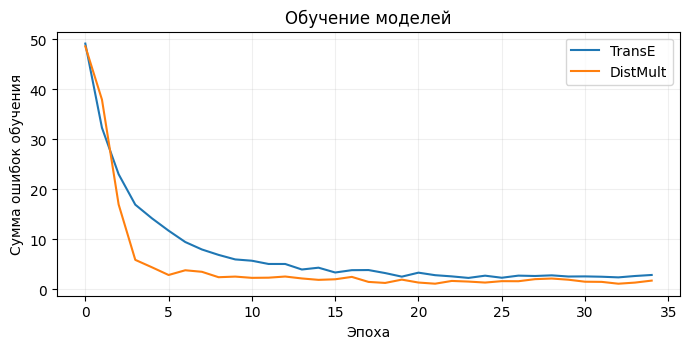

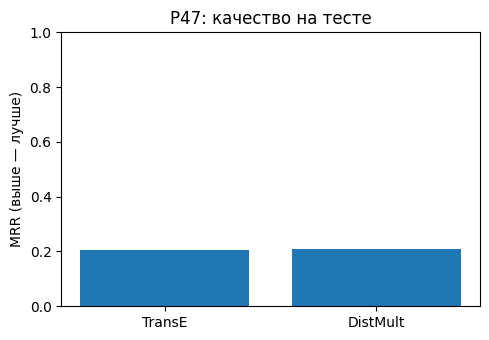

In [12]:
plt.figure(figsize=(7,3.6))
plt.plot(loss_tr,label='TransE')
plt.plot(loss_dm,label='DistMult')
plt.xlabel('Эпоха');plt.ylabel('Сумма ошибок обучения')
plt.title('Обучение моделей');plt.legend();plt.grid(alpha=0.2)
plt.tight_layout();plt.savefig(OUTPUT/'loss.png',dpi=130)
plt.show()

names = ['TransE','DistMult']
values = [test_borders[x]['MRR'] for x in names]
plt.figure(figsize=(5,3.5))
plt.bar(names,values)
plt.ylim(0,1);plt.ylabel('MRR (выше — лучше)')
plt.title('P47: качество на тесте');plt.tight_layout()
plt.savefig(OUTPUT/'mrr.png',dpi=130)
plt.show()

In [13]:
summary = {
 'endpoint': ENDPOINT, 'retrieved_at_utc': retrieved_at,
 'border_query': BORDERS_QUERY, 'attributes_query': ATTRIBUTES_QUERY,
 'border_types_query': BORDER_TYPES_QUERY,
 'border_features_query': BORDER_FEATURES_QUERY,
 'labels_query': LABELS_QUERY,
 'label_count': len(labels),
 'variant':57,'mapped_variant':27,'seed':SEED,'dimension':DIM,
 'node2vec_p':P,'node2vec_q':Q,'margin':MARGIN,
 'countries':len(countries),'border_pairs':len(border_pairs),
 'raw_border_statements':len(raw_borders),
 'kge_resource_triples':len(triples),
 'typed_border_triples':len(typed_border_triples),
 'shared_attribute_rows':len(shared_attributes),
 'border_type_counts':border_details['types'].value_counts().to_dict(),
 'border_pairs_with_object':int(border_details.border_objects.ne('').sum()),
 'border_pairs_with_feature':int(border_details.physical_features.ne('').sum()),
 'numeric_literal_triples':len(countries),'rdf_triples':len(graph),
 'kge_entities':len(entities),'relations':relations,
 'split':{'train':len(train),'validation':len(valid),'test':len(test)},
 'validation_relation_counts':validation_relation_counts.to_dict(),
 'test_relation_counts':test_relation_counts.to_dict(),
 'positive_triple':positive,'negative_triple':negative,
 'positive_distance':positive_distance,'negative_distance':negative_distance,
 'margin_loss':margin_loss,
 'validation':validation_results,'validation_P47':validation_borders,
 'test':test_results,'test_P47':test_borders,
 'selected_on_validation_P47':selected}
(OUTPUT/'metrics.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
np.savez(OUTPUT/'embeddings.npz',transe_entities=E_tr,transe_relations=R_tr,
         distmult_entities=E_dm,distmult_relations=R_dm,walk_vectors=walk_vectors,
         entities=np.array(entities),relations=np.array(relations))
print('Файлы сохранены в',OUTPUT)

Файлы сохранены в C:\Users\nasty\Semantic_technologies\seminar_topic5_variant57\results


## 11. Визуализация эмбеддингов стран: PCA и t-SNE

PCA показывает две главные компоненты и долю объяснённой ими дисперсии. t-SNE помогает рассмотреть локальные соседства. Оси t-SNE и расстояния между далёкими группами не имеют географического смысла. На рисунках показаны только страны, связанные P47, без столиц и других сущностей.

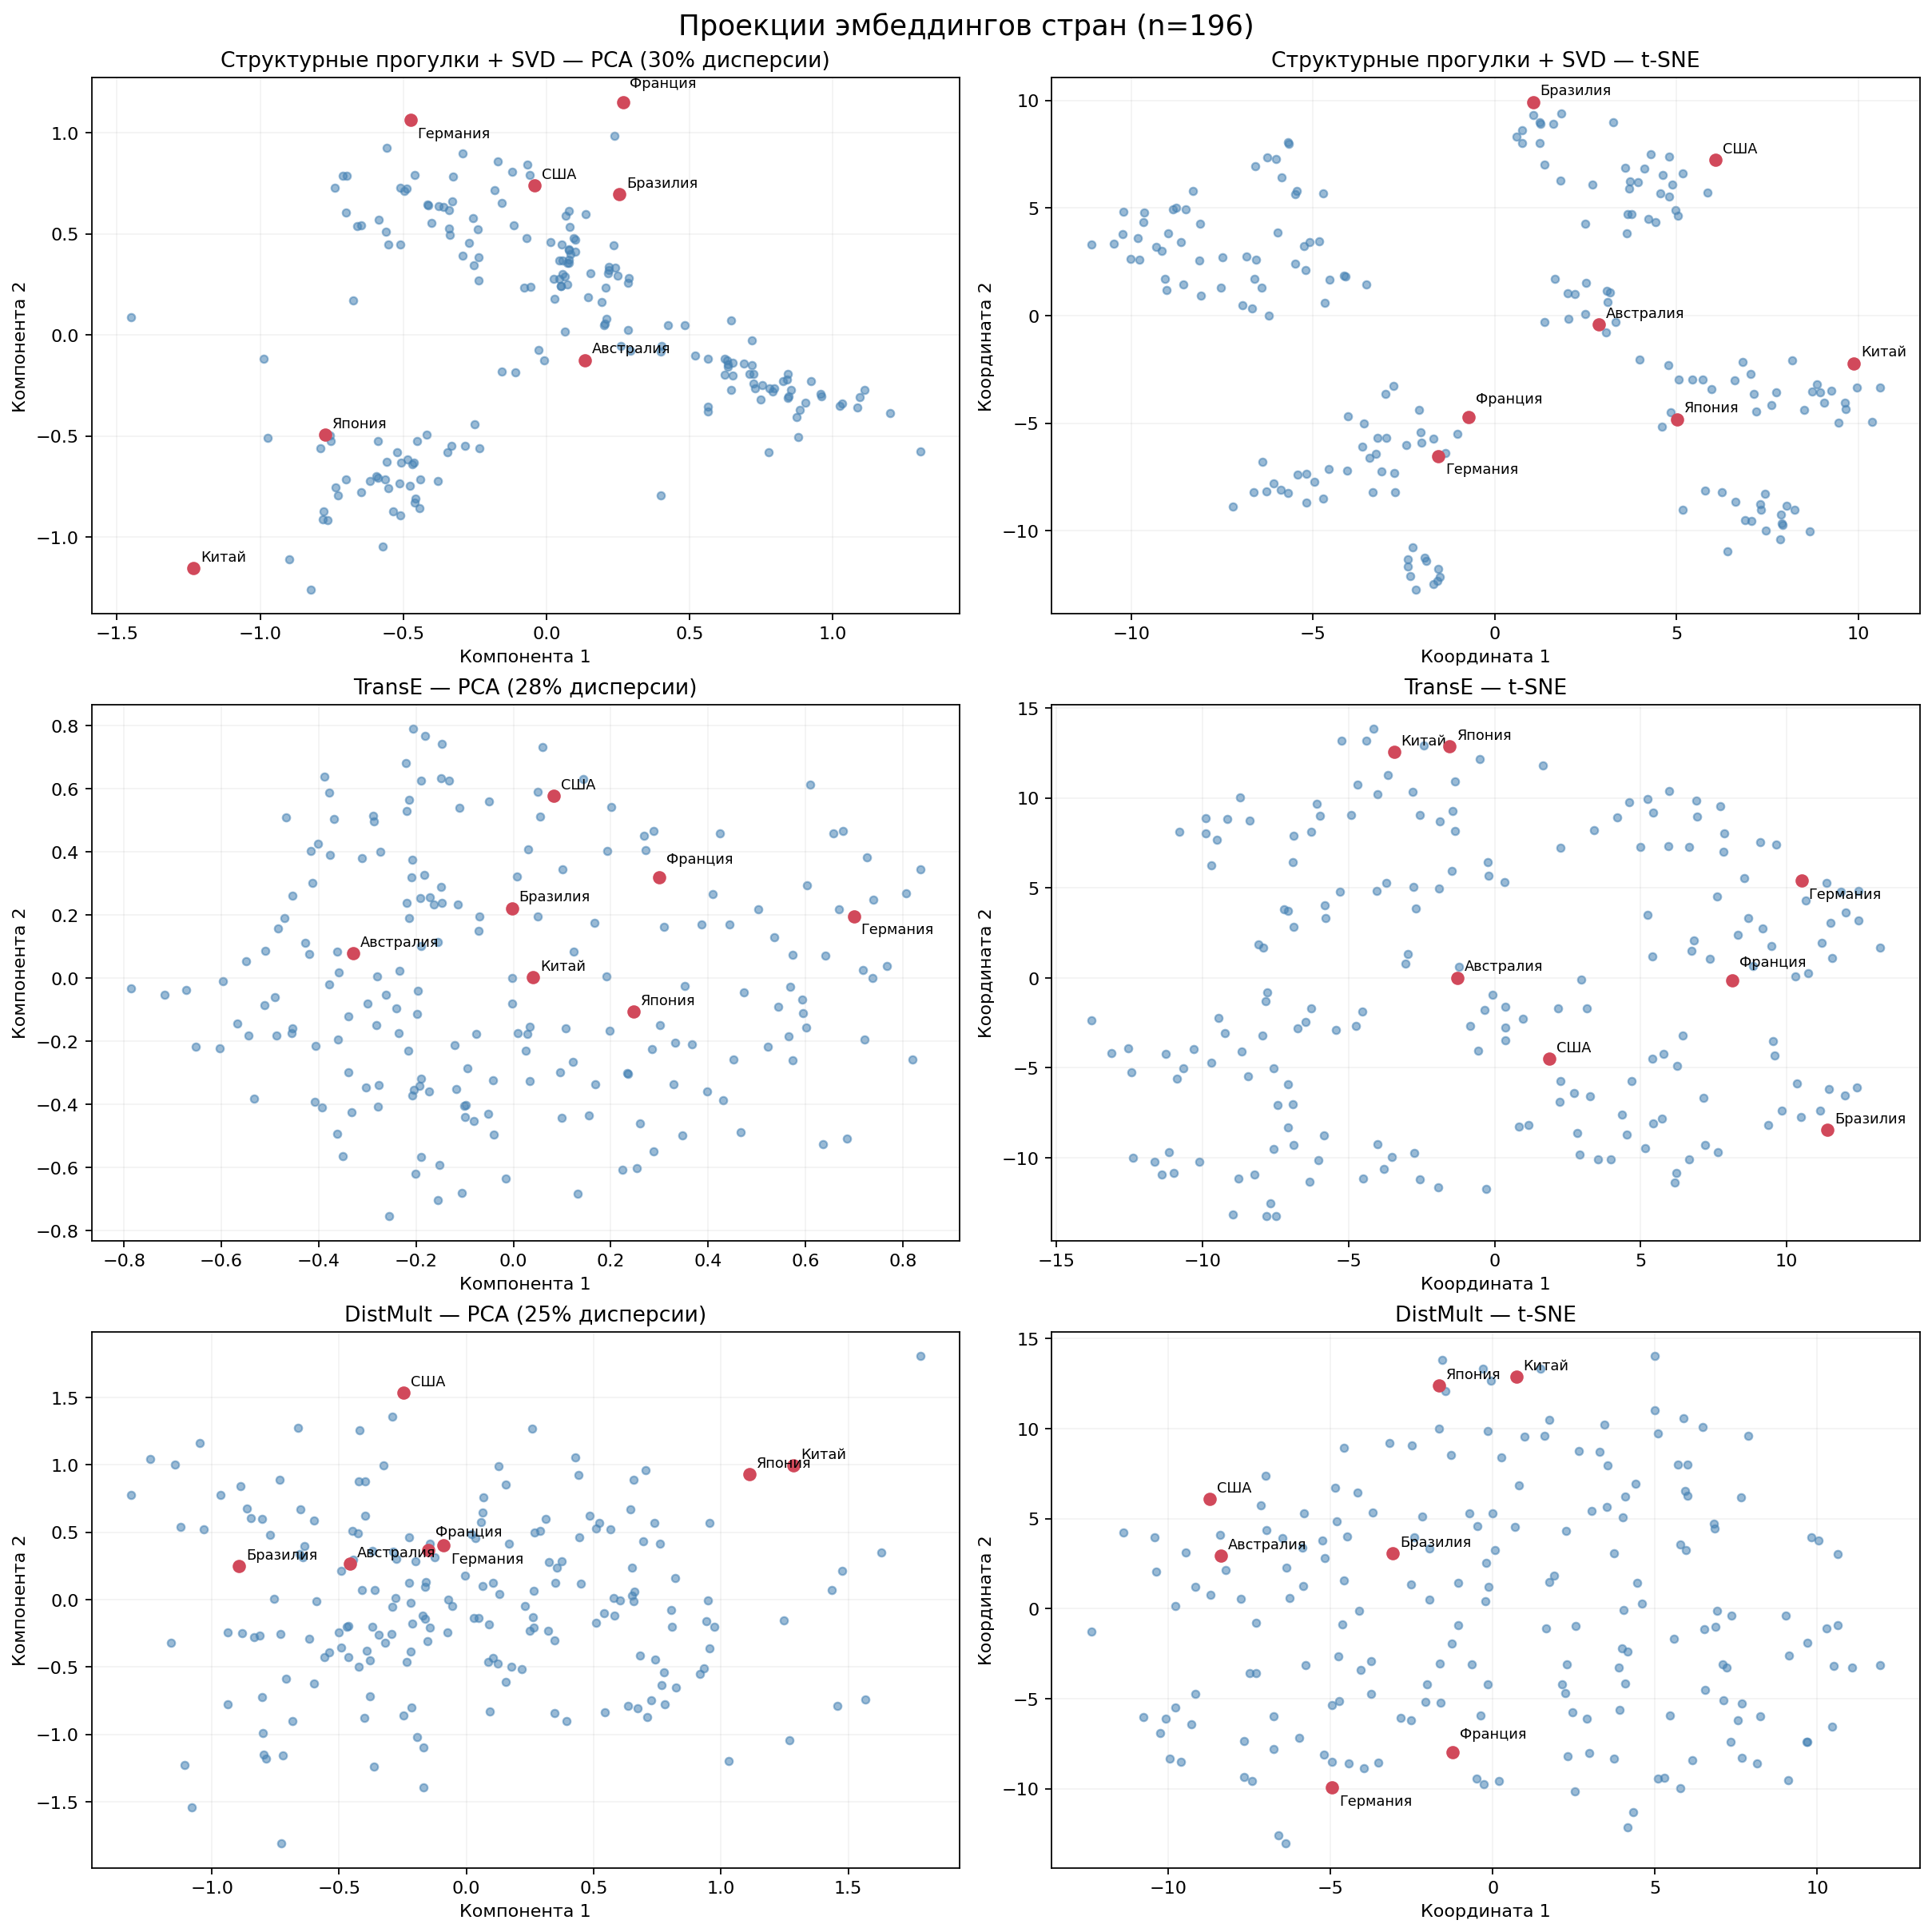

In [14]:
from plot_embeddings import plot_embeddings
from IPython.display import Image, display

projection_path = plot_embeddings(OUTPUT)
display(Image(filename=str(projection_path)))

## Вывод

Граф содержит исходные P47/P36/P37/P38/P30 и отдельные производные связи: подтверждённые суша/вода/точка, пограничный объект, физический объект, общий официальный язык и общая валюта. Неизвестный тип не угадывается. Одна пара может иметь несколько типов. Типы границ и общие свойства сохраняются с происхождением в TSV/JSON, но не добавляются в KGE, чтобы не раскрыть отложенные факты. Два SPARQL-запроса, Turtle, TransE/DistMult, margin loss, MRR/Hits и три ошибки находятся выше. Вывод о модели делается по validation P47.